# BÀI THỰC HÀNH 2 - BÀI 5a (TRANG 45)
## KHAI THÁC LUẬT KẾT HỢP DỮ LIỆU NƯỚC ĐỨC (GERMANY)
- **Học viên:** Nguyễn Minh Vương
- **MSSV:** 6451071090
- **Môn học:** Khai thác dữ liệu
- **Yêu cầu:** Thực hiện khai thác tập phổ biến và luật kết hợp cho nước Đức 'Germany' với `min_sup = 5%` và `min_conf = 50%`

In [3]:
# Cài đặt thư viện nếu chạy trên Google Colab
# !pip install pandas numpy matplotlib seaborn mlxtend openpyxl gdown

import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
%matplotlib inline

# Tự động tải thư mục dataset từ link Google Drive
if not os.path.exists("dataset") or len(os.listdir("dataset")) == 0:
    try:
        import gdown
        drive_folder_url = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m"
        print("Đang tải dataset từ Google Drive...")
        gdown.download_folder(drive_folder_url, output="dataset", quiet=False, use_cookies=False)
        print("✅ Tải dataset thành công!")
    except Exception as e:
        print("Lưu ý: Nếu chưa có thư viện gdown, hãy chạy lệnh: !pip install gdown")

print("Nguyễn Minh Vương - 6451071090")


Nguyễn Minh Vương - 6451071090


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 1. Đọc dữ liệu và tiền xử lý làm sạch dữ liệu ban đầu

In [4]:
print("Nguyễn Minh Vương - 6451071090")

df = pd.read_excel('dataset/Online Retail.xlsx')

# Tiền xử lý dữ liệu
df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

print(f"Kích thước tập dữ liệu sau khi làm sạch: {df.shape[0]} dòng, {df.shape[1]} cột")
display(df.head())


Nguyễn Minh Vương - 6451071090
Kích thước tập dữ liệu sau khi làm sạch: 532621 dòng, 8 cột


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 2. Lọc dữ liệu khách hàng nước Đức ('Germany') và tạo ma trận One-hot encoding giỏ hàng

In [6]:
print("Nguyễn Minh Vương - 6451071090")

# Gom nhóm theo hóa đơn và mặt hàng của nước Đức 'Germany'
basket_germany = (df[df['Country'] == "Germany"]
                  .groupby(['InvoiceNo', 'Description'])['Quantity'].sum()
                  .unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

# Hàm chuẩn hóa sang One-hot encoding (0 hoặc 1)
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

basket_germany = basket_germany.map(encode_units) if hasattr(basket_germany, 'map') else basket_germany.applymap(encode_units)

# Xóa cột cước phí POSTAGE nếu có
if 'POSTAGE' in basket_germany.columns:
    basket_germany.drop('POSTAGE', inplace=True, axis=1)

print(f"Ma trận giỏ hàng thị trường Đức: {basket_germany.shape[0]} hóa đơn, {basket_germany.shape[1]} mặt hàng")
display(basket_germany.iloc[:5, :8])


Nguyễn Minh Vương - 6451071090
Ma trận giỏ hàng thị trường Đức: 457 hóa đơn, 1694 mặt hàng


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536527,0,0,0,0,0,0,0,0
536840,0,0,0,0,0,0,0,0
536861,0,0,0,0,0,0,0,0
536967,0,0,0,0,0,0,0,0
536983,0,0,0,0,0,0,0,0


### 3. Tìm tập phổ biến bằng giải thuật Apriori và FP-Growth với min_sup = 5%

In [7]:
print("Nguyễn Minh Vương - 6451071090")

# Áp dụng Apriori với min_sup = 5% (0.05)
itemsets_germany_apriori = apriori(basket_germany, min_support=0.05, use_colnames=True)
print(f"Số lượng tập phổ biến tìm được bằng Apriori (min_sup=5%): {len(itemsets_germany_apriori)}")

# Áp dụng FP-Growth để đối chiếu
itemsets_germany_fpgrowth = fpgrowth(basket_germany, min_support=0.05, use_colnames=True)
print(f"Số lượng tập phổ biến tìm được bằng FP-Growth (min_sup=5%): {len(itemsets_germany_fpgrowth)}\n")

print("10 tập mục phổ biến đầu tiên:")
display(itemsets_germany_apriori.head(10))


Nguyễn Minh Vương - 6451071090
Số lượng tập phổ biến tìm được bằng Apriori (min_sup=5%): 59
Số lượng tập phổ biến tìm được bằng FP-Growth (min_sup=5%): 59

10 tập mục phổ biến đầu tiên:


,support,itemsets
0,0.102845,(6 RIBBONS RUSTIC CHARM)
1,0.070022,(ALARM CLOCK BAKELIKE PINK)
2,0.065646,(CHARLOTTE BAG APPLES DESIGN)
3,0.050328,(CHILDRENS CUTLERY DOLLY GIRL)
4,0.061269,(COFFEE MUG APPLES DESIGN)
5,0.063457,(FAWN BLUE HOT WATER BOTTLE)
6,0.072210,(GUMBALL COAT RACK)
7,0.056893,(IVORY KITCHEN SCALES)
8,0.063457,(JAM JAR WITH PINK LID)
9,0.091904,(JAM MAKING SET PRINTED)


### 4. Tạo luật kết hợp với min_conf = 50% (0.5) và in ra các luật

In [8]:
print("Nguyễn Minh Vương - 6451071090")

# Sinh luật kết hợp với độ tin cậy tối thiểu 50%
rules_germany = association_rules(itemsets_germany_apriori, metric="confidence", min_threshold=0.5)

print(f"Tổng số luật kết hợp tìm được cho thị trường Đức: {len(rules_germany)}\n")

rules_disp = rules_germany.copy()
rules_disp['antecedents'] = rules_disp['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_disp['consequents'] = rules_disp['consequents'].apply(lambda x: ', '.join(list(x)))

for i in range(len(rules_disp)):
    print(f"Luật {i+1}: {rules_disp.loc[i, 'antecedents']}  ==>  {rules_disp.loc[i, 'consequents']}")
    print(f"         Support: {rules_disp.loc[i, 'support']:.4f} | Confidence: {rules_disp.loc[i, 'confidence']:.4f} | Lift: {rules_disp.loc[i, 'lift']:.4f}\n")


Nguyễn Minh Vương - 6451071090
Tổng số luật kết hợp tìm được cho thị trường Đức: 8

Luật 1: PLASTERS IN TIN CIRCUS PARADE  ==>  PLASTERS IN TIN WOODLAND ANIMALS
         Support: 0.0678 | Confidence: 0.5849 | Lift: 4.2429

Luật 2: PLASTERS IN TIN SPACEBOY  ==>  PLASTERS IN TIN WOODLAND ANIMALS
         Support: 0.0613 | Confidence: 0.5714 | Lift: 4.1451

Luật 3: PLASTERS IN TIN WOODLAND ANIMALS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND
         Support: 0.0744 | Confidence: 0.5397 | Lift: 2.2021

Luật 4: RED RETROSPOT CHARLOTTE BAG  ==>  WOODLAND CHARLOTTE BAG
         Support: 0.0591 | Confidence: 0.8438 | Lift: 6.6482

Luật 5: ROUND SNACK BOXES SET OF 4 FRUITS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND
         Support: 0.1313 | Confidence: 0.8333 | Lift: 3.4003

Luật 6: ROUND SNACK BOXES SET OF4 WOODLAND  ==>  ROUND SNACK BOXES SET OF 4 FRUITS
         Support: 0.1313 | Confidence: 0.5357 | Lift: 3.4003

Luật 7: SPACEBOY LUNCH BOX  ==>  ROUND SNACK BOXES SET OF4 WOODLAND
         Suppo

### 5. Vẽ biểu đồ phân tán (scatter plot) biểu diễn các luật kết hợp và đưa ra nhận xét

Nguyễn Minh Vương - 6451071090


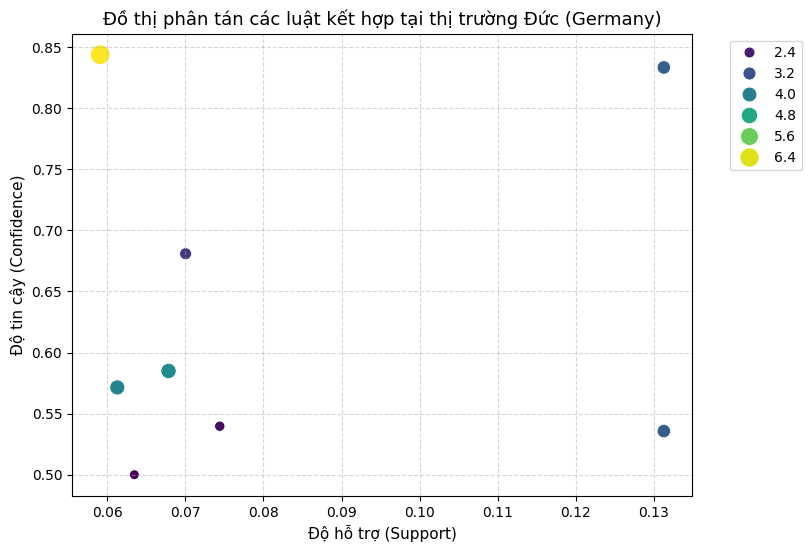

In [9]:
print("Nguyễn Minh Vương - 6451071090")

plt.figure(figsize=(8, 6))
plt.title('Đồ thị phân tán các luật kết hợp tại thị trường Đức (Germany)', fontsize=13)
plt.xlabel('Độ hỗ trợ (Support)', fontsize=11)
plt.ylabel('Độ tin cậy (Confidence)', fontsize=11)

sns.scatterplot(x='support', y='confidence', size='lift', hue='lift', data=rules_germany, palette='viridis', sizes=(50, 200))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()
